In [ ]:
import tensorflow as tf

print("=" * 50)
print("TensorFlow Version:", tf.__version__)
print("=" * 50)

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("✅ GPU Available")
    print(gpus)
else:
    print("❌ GPU NOT Available")

TensorFlow Version: 2.20.0
✅ GPU Available
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!pip install -q opencv-python seaborn

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

In [4]:
!unzip -q /content/archive-3.zip -d /content/

In [5]:
train_dir = "/content/archive-3/train"
test_dir = "/content/archive-3/test"

print("Train:", os.path.exists(train_dir))
print("Test :", os.path.exists(test_dir))

Train: True
Test : True


In [6]:
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.0001
NUM_CLASSES = 7

In [7]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [8]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    color_mode="rgb"
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

Found 28707 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


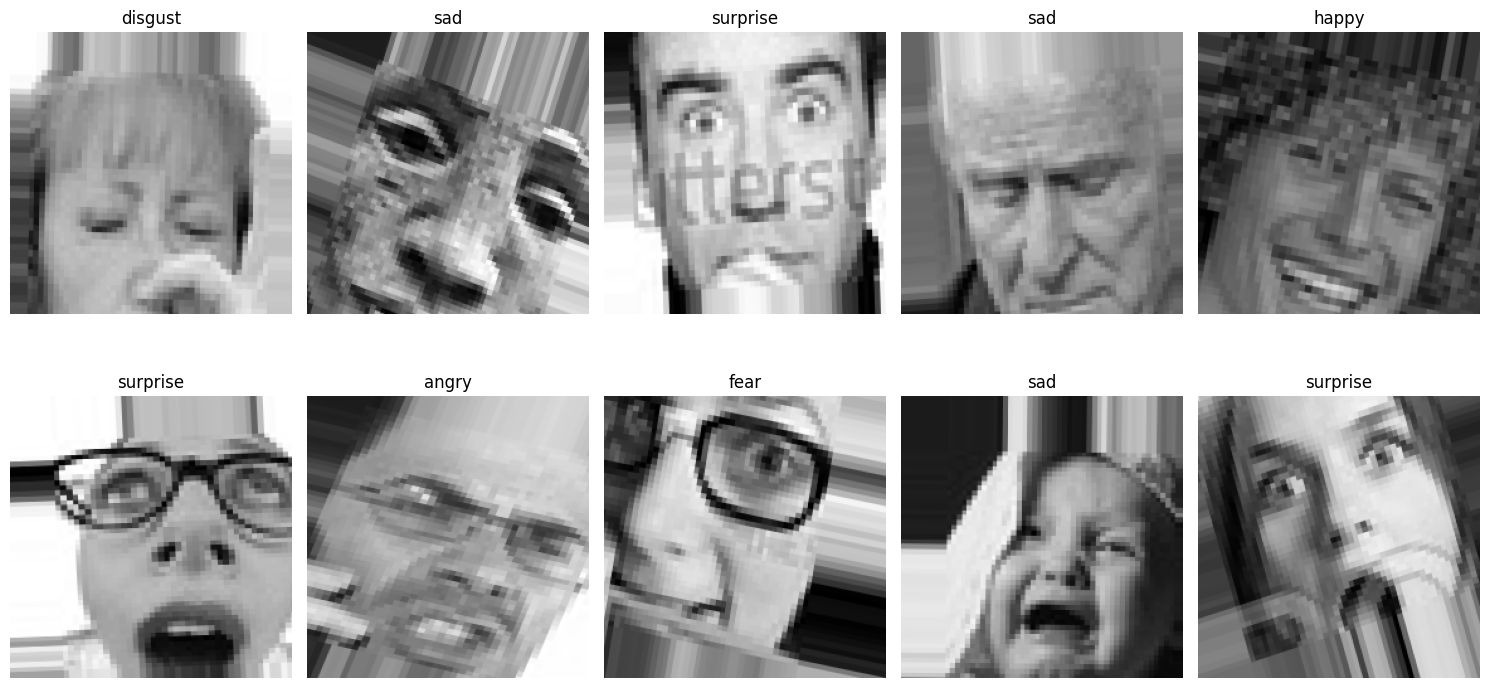

In [9]:
images, labels = next(train_generator)

plt.figure(figsize=(15,8))

class_names = list(train_generator.class_indices.keys())

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

print("✅ Base Model Loaded Successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ Base Model Loaded Successfully!


In [11]:
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.5)(x)

x = Dense(512, activation="relu")(x)

x = BatchNormalization()(x)

x = Dropout(0.3)(x)

outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)

print("✅ Emotion Recognition Model Created")

✅ Emotion Recognition Model Created


In [12]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,924,615 (11.16 MB)

 Trainable params: 663,047 (2.53 MB)

 Non-trainable params: 2,261,568 (8.63 MB)

In [13]:
Dense (7)

<Dense name=dense_2, built=False>

In [14]:
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Model Compiled Successfully")

✅ Model Compiled Successfully


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
import os

os.makedirs("/content/drive/MyDrive/DeepFER/Models", exist_ok=True)

In [17]:
checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/DeepFER/Models/best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

In [18]:
import time

start = time.time()

history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ],
    verbose=1
)

end = time.time()

print(f"\nTraining Time: {(end-start)/60:.2f} minutes")

Epoch 1/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.2187 - loss: 2.4538
Epoch 1: val_accuracy improved from None to 0.38646, saving model to /content/drive/MyDrive/DeepFER/Models/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepFER/Models/best_model.keras
898/898 ━━━━━━━━━━━━━━━━━━━━ 433s 458ms/step - accuracy: 0.2560 - loss: 2.2734 - val_accuracy: 0.3865 - val_loss: 1.6783 - learning_rate: 1.0000e-04
Epoch 2/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step - accuracy: 0.3039 - loss: 2.0198
Epoch 2: val_accuracy improved from 0.38646 to 0.40945, saving model to /content/drive/MyDrive/DeepFER/Models/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepFER/Models/best_model.keras
898/898 ━━━━━━━━━━━━━━━━━━━━ 363s 404ms/step - accuracy: 0.3095 - loss: 1.9788 - val_accuracy: 0.4094 - val_loss: 1.6041 - learning_rate: 1.0000e-04
Epoch 3/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.3263 - loss: 1.8575
Epoch 3

In [19]:
model.save("/content/drive/MyDrive/DeepFER/Models/final_emotion_model.keras")

print("✅ Final model saved successfully!")

✅ Final model saved successfully!


In [21]:
import os

os.makedirs("/content/drive/MyDrive/DeepFER/Results", exist_ok=True)

print("✅ Results folder created")

✅ Results folder created


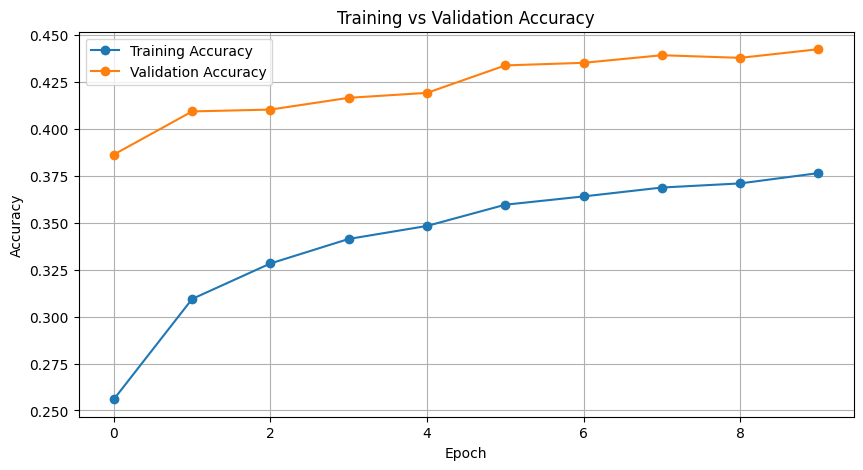

In [22]:
plt.figure(figsize=(10,5))

plt.plot(history.history['accuracy'],
         marker='o',
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         marker='o',
         label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.savefig("/content/drive/MyDrive/DeepFER/Results/accuracy.png")

plt.show()

In [23]:
test_generator.reset()

predictions = model.predict(test_generator)

predicted_classes = np.argmax(predictions, axis=1)

true_classes = test_generator.classes

class_labels = list(test_generator.class_indices.keys())

print("Prediction Completed")

225/225 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step
Prediction Completed


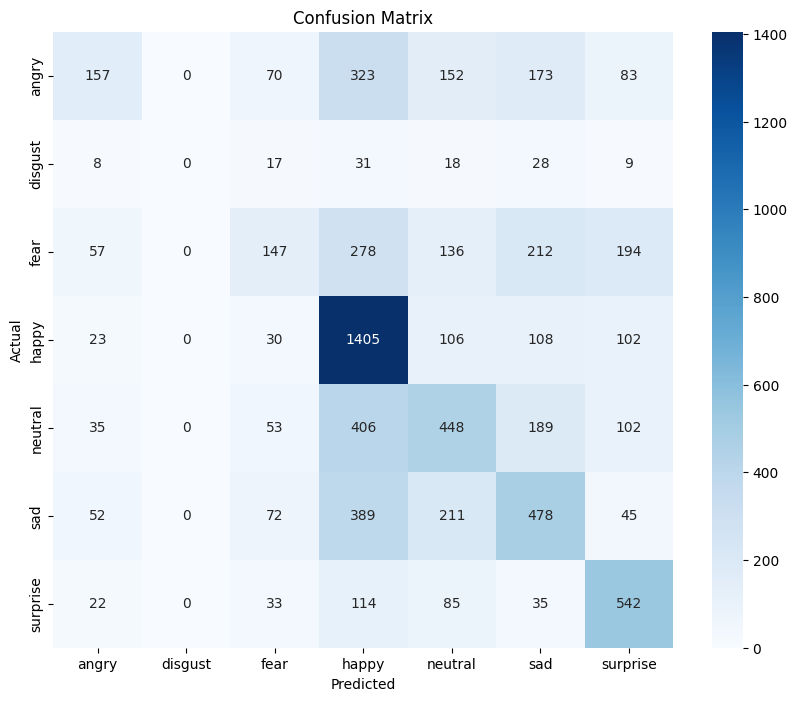

In [24]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("/content/drive/MyDrive/DeepFER/Results/confusion_matrix.png")

plt.show()

In [25]:
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_labels
)

print(report)

with open("/content/drive/MyDrive/DeepFER/Results/classification_report.txt", "w") as f:
    f.write(report)

print("✅ Classification report saved successfully!")

              precision    recall  f1-score   support

       angry       0.44      0.16      0.24       958
     disgust       0.00      0.00      0.00       111
        fear       0.35      0.14      0.20      1024
       happy       0.48      0.79      0.60      1774
     neutral       0.39      0.36      0.38      1233
         sad       0.39      0.38      0.39      1247
    surprise       0.50      0.65      0.57       831

    accuracy                           0.44      7178
   macro avg       0.36      0.36      0.34      7178
weighted avg       0.42      0.44      0.41      7178

✅ Classification report saved successfully!


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
